# 01 - Reproduction: published results vs v0 vs v1

Does our run of the authors' code (**v0**, their unmodified `run.py`) reproduce the **published** accuracies, does
adding timers and metrics (**v1**) leave the method unchanged, and does the timing claim hold (under 15 minutes for
the 142 datasets on one CPU core)? All three on the same 142 datasets x 30 resamples. Settings and commands:
`experiments.md` (v0, v1); data and its preparation: the README, section 2.

## 1. Data

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# the shared paths and colours of all notebooks: notebooks/common.py (this notebook keeps matplotlib's own style)
from common import (PHASE_COLORS, PUBLISHED_FILE, RESULTS_DIR, VERSION_COLORS, WARNING, WORSE, count_test_cases, holm)

V0_FILE = RESULTS_DIR / "v0_ucr142_onecore-cpu.csv"            # the authors' run.py, unmodified, one CPU core
V1_FILE = RESULTS_DIR / "v1_ucr142_onecore-cpu.csv"            # v1, ExtraTrees, seed 0, one CPU core

PAPER_MEAN_142 = 0.8568             # Fig. 6
PAPER_MEAN_112 = 0.8671             # Fig. 1
PAPER_CLAIM_MIN = 15                # abstract: "less than 15 minutes using a single CPU core"

# the 30 datasets added by the bake-off redux; the other 112 are the original UCR datasets
NEW30 = [
    "AconityMINIPrinterLargeEq", "AconityMINIPrinterSmallEq", "AllGestureWiimoteXEq", "AllGestureWiimoteYEq",
    "AllGestureWiimoteZEq", "AsphaltObstaclesUniEq", "AsphaltPavementTypeUniEq", "AsphaltRegularityUniEq",
    "Colposcopy", "Covid3MonthDiscrete", "DodgerLoopDayNmv", "DodgerLoopGameNmv", "DodgerLoopWeekendNmv",
    "ElectricDeviceDetection", "FloodModeling1Discrete", "FloodModeling2Discrete", "FloodModeling3Discrete",
    "GestureMidAirD1Eq", "GestureMidAirD2Eq", "GestureMidAirD3Eq", "GesturePebbleZ1Eq", "GesturePebbleZ2Eq",
    "KeplerLightCurves", "MelbournePedestrianNmv", "PLAIDEq", "PhoneHeartbeatSound", "PickupGestureWiimoteZEq",
    "ShakeGestureWiimoteZEq", "SharePriceIncrease", "Tools",
]
# the 4 datasets corrected after the bake-off pre-print, with their corrected test-set sizes
CORRECTED = {"Covid3MonthDiscrete": 61, "FloodModeling1Discrete": 202,
             "FloodModeling2Discrete": 201, "FloodModeling3Discrete": 184}

PAIRS = [("v0", "published"), ("v1", "published"), ("v1", "v0")]      # each pair is compared as first - second
PAIR_COLORS = {"v0 - published": VERSION_COLORS["v0"], "v1 - published": VERSION_COLORS["v1"], "v1 - v0": VERSION_COLORS["v1 - v0"]}
# v1's time columns, with the label and the colour of each phase
PHASES = {"time_transform_train": ("QUANT transform, train", PHASE_COLORS["transform train"]),
          "time_fit": ("fit", PHASE_COLORS["fit"]),
          "time_transform_test": ("QUANT transform, test", PHASE_COLORS["transform test"]),
          "time_predict": ("predict", PHASE_COLORS["predict"])}

In [2]:
published = pd.read_csv(PUBLISHED_FILE, index_col=0)

def wide(runs):
    """One row per dataset, one column per resample, in the same order as the published file."""
    table = runs.pivot(index="dataset", columns="resample", values="accuracy")
    table.columns = table.columns.astype(str)            # resample numbers as text ("0".."29"), as in the published file
    return table.loc[published.index, published.columns]

v0 = wide(pd.read_csv(V0_FILE))
v1_runs = pd.read_csv(V1_FILE)                           # also has the per-phase times (Part B)
v1 = wide(v1_runs)
RESULTS = {"published": published, "v0": v0, "v1": v1}
for name, table in RESULTS.items():
    assert table.shape == (142, 30) and table.notna().all().all(), name     # every run is there

ORIGINAL = [name for name in published.index if name not in NEW30]          # the 112 original UCR datasets
UNCHANGED = [name for name in published.index if name not in CORRECTED]     # the 138 datasets as they were for the paper
SAME = {name: table.loc[UNCHANGED] for name, table in RESULTS.items()}       # the three results on those 138
n_test = pd.Series({name: count_test_cases(name) for name in published.index})   # the test-set size of every dataset
assert len(ORIGINAL) == 112 and len(UNCHANGED) == 138

## 2. Four datasets changed after the paper

Covid3MonthDiscrete and FloodModeling1-3Discrete were corrected after the paper: our files have the corrected test
sets (left), so on these 4 the published results and ours use different data (right). Sections 4, 5 and 7 use the
other 138; section 6 shows both.

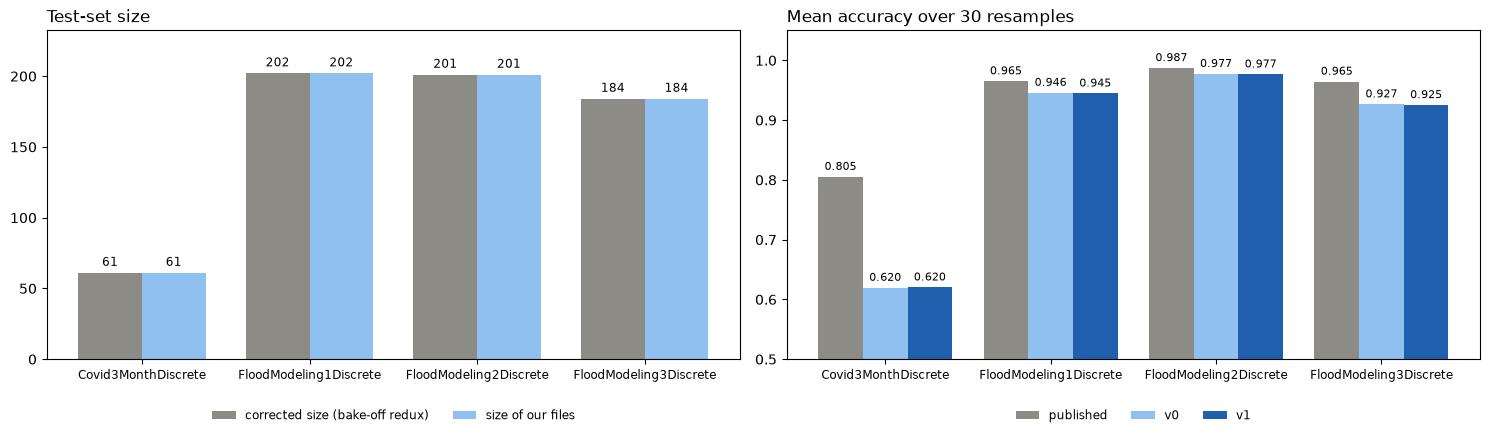

In [3]:
names = list(CORRECTED)
x = np.arange(len(names))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

# left: the corrected test-set sizes and the sizes of our files
bars = ax1.bar(x - 0.19, list(CORRECTED.values()), 0.38, color=VERSION_COLORS["published"],
               label="corrected size (bake-off redux)")
ax1.bar_label(bars, fmt="{:.0f}", padding=3, fontsize=8.5)
bars = ax1.bar(x + 0.19, n_test[names], 0.38, color=VERSION_COLORS["v0"], label="size of our files")
ax1.bar_label(bars, fmt="{:.0f}", padding=3, fontsize=8.5)
ax1.set_ylim(0, max(CORRECTED.values()) * 1.15)
ax1.set_title("Test-set size", loc="left")

# right: the mean accuracy of the three results on these 4 datasets
for offset, (name, table) in zip([-0.27, 0, 0.27], RESULTS.items()):
    bars = ax2.bar(x + offset, table.loc[names].mean(axis=1), 0.27, color=VERSION_COLORS[name], label=name)
    ax2.bar_label(bars, fmt="{:.3f}", padding=3, fontsize=8)
ax2.set_ylim(0.5, 1.05)
ax2.set_title("Mean accuracy over 30 resamples", loc="left")

for ax in (ax1, ax2):
    ax.set_xticks(x, names, fontsize=8.5)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

## 3. How two results are compared

For a pair a - b, per dataset: the mean difference over the 30 resamples (in accuracy and in test cases); a two-sided
Wilcoxon signed-rank test on the 30 paired resamples (lecture week 9, p.6-9: the same splits for both, so the
resamples are paired), p >= 0.05 = within noise, with Holm's correction for the 138 tests (week 9, p.5); and the
Pearson correlation of a and b across the resamples (clearly positive = the same splits). Resamples share training and
test series, so per-dataset tests are optimistic (week 9, p.10): Holm's correction decides. Per subset: a Wilcoxon
signed-rank test across the datasets.

In [4]:
def paired_p(x, y):
    """Two-sided Wilcoxon signed-rank test of one dataset's 30 paired resamples (p = 1 if the two never differ)."""
    if (x - y).abs().max() == 0:
        return 1.0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")              # ties among the differences: scipy's normal approximation
        return stats.wilcoxon(x, y).pvalue

def compare(a, b):
    """Per dataset: the difference a - b of the means over the resamples, a Wilcoxon test of the paired resamples,
    Holm, the split correlation."""
    d = pd.DataFrame(index=a.index)
    d["diff"] = a.mean(axis=1) - b.mean(axis=1)
    d["diff_cases_mean"] = d["diff"] * n_test[a.index]                     # the same difference in test cases
    d["p"] = [paired_p(a.loc[name], b.loc[name]) for name in a.index]      # the 30 resamples, paired
    d["p_holm"] = holm(d["p"])
    d["within_noise"] = d["p"] >= 0.05
    d["significant_holm"] = d["p_holm"] < 0.05
    with np.errstate(invalid="ignore", divide="ignore"):    # a constant accuracy (e.g. 1.0 everywhere) has no correlation
        d["split_corr"] = [a.loc[name].corr(b.loc[name]) for name in a.index]
    return d

# the three pairs on the 138 unchanged datasets, e.g. per_pair["v0 - published"]
per_pair = {f"{a} - {b}": compare(SAME[a], SAME[b]) for a, b in PAIRS}

# Part A - Accuracy: published vs v0 vs v1 (the 138 unchanged datasets)

## 4. Differences per run, in test cases

One count per run (138 datasets x 30 splits): how many more test cases one result got right than the other.
v1 - v0 is the same method twice, only ExtraTrees' randomness differs: the noise the other two panels compare with.

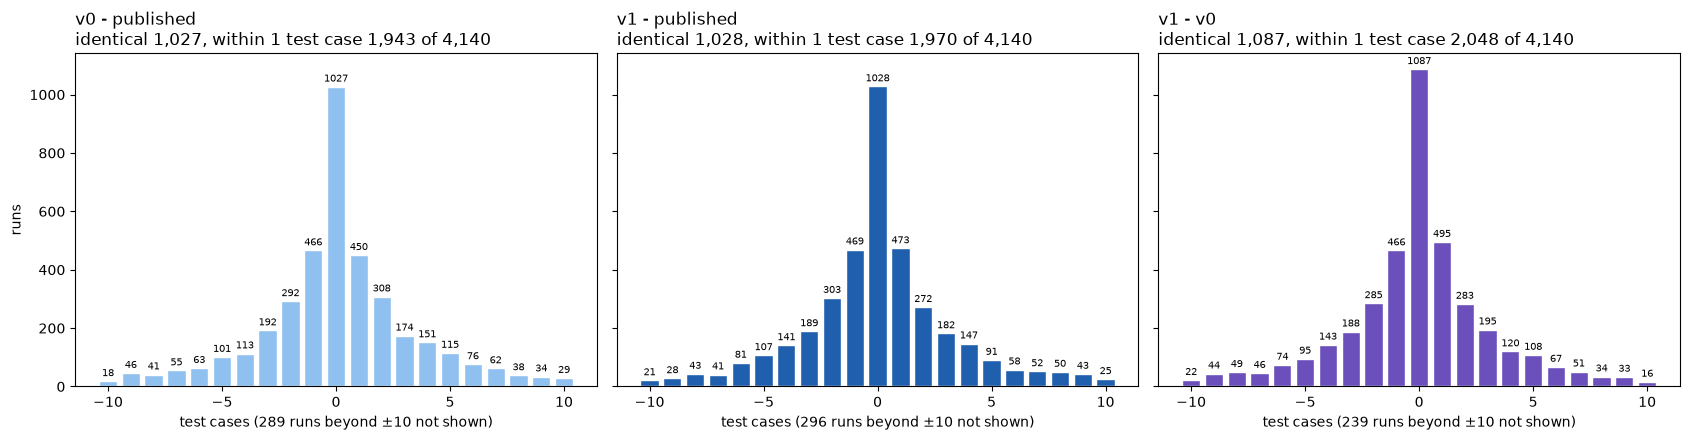

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (a, b) in zip(axes, PAIRS):
    name = f"{a} - {b}"
    diff = SAME[a] - SAME[b]                                         # the accuracy difference of every run
    cases = diff.mul(n_test[UNCHANGED], axis=0).round()              # each row times its test-set size: test cases
    cases = cases.stack()                                            # the table as one long list of runs
    counts = cases.value_counts().sort_index()                       # how many runs have each difference
    shown = counts[(counts.index >= -10) & (counts.index <= 10)]
    bars = ax.bar(shown.index, shown.values, color=PAIR_COLORS[name], edgecolor="white")
    ax.bar_label(bars, padding=2, fontsize=7)
    identical = (diff.abs() < 1e-6).sum().sum()
    within_one = (cases.abs() <= 1).sum()
    ax.set_title(f"{name}\nidentical {identical:,}, within 1 test case {within_one:,} of {cases.size:,}", loc="left")
    ax.set_xlabel(f"test cases ({(cases.abs() > 10).sum()} runs beyond ±10 not shown)")
axes[0].set_ylabel("runs")
plt.tight_layout()
plt.show()

## 5. Per dataset: is the difference within the expected noise?

The mean difference of every dataset, sorted. Yellow: p < 0.05 in the Wilcoxon test of the paired resamples (about 7
expected by chance); red: still significant after Holm; both are named in the box.

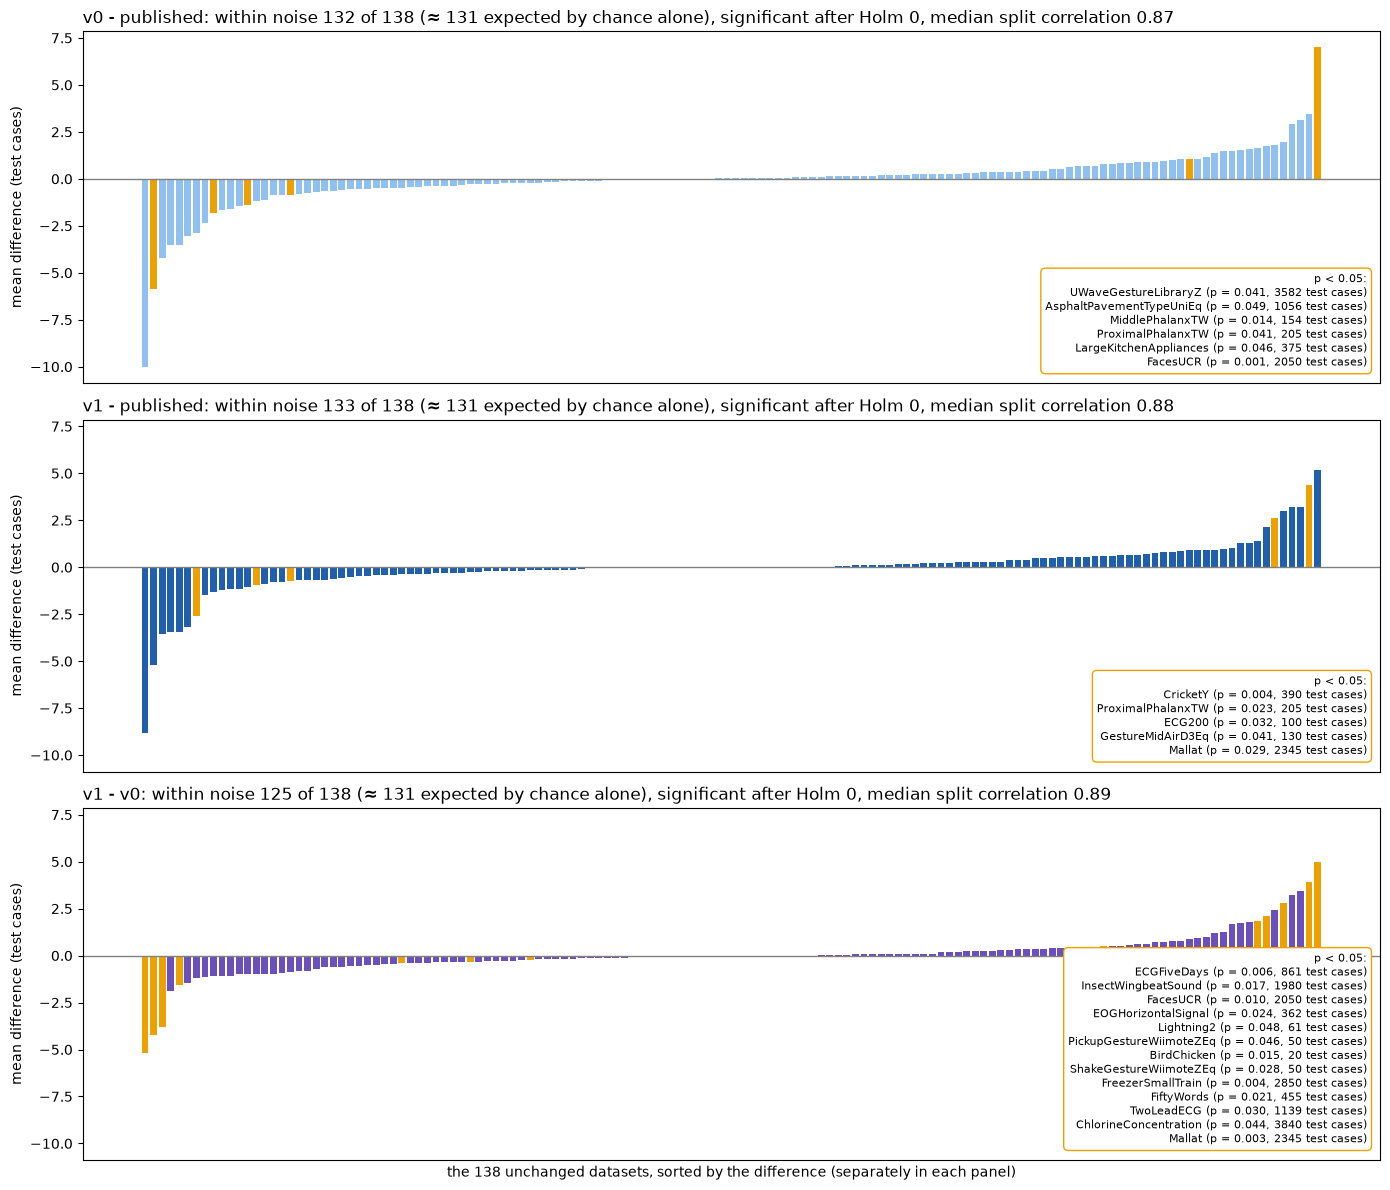

In [6]:
def bar_color(row, pair):
    """Red: significant after Holm; yellow: p < 0.05 before the correction; otherwise the colour of the pair."""
    if row["significant_holm"]:
        return WORSE
    if not row["within_noise"]:
        return WARNING
    return PAIR_COLORS[pair]

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharey=True)
for ax, (name, d) in zip(axes, per_pair.items()):
    order = d.sort_values("diff_cases_mean")
    ax.bar(np.arange(len(order)), order["diff_cases_mean"], width=0.8,
           color=[bar_color(row, name) for _, row in order.iterrows()])
    ax.axhline(0, color="grey", linewidth=1)

    # the datasets with p < 0.05 are named in a box (labels on the bars would overlap)
    lines = []
    for dataset, row in order[~order["within_noise"]].iterrows():
        holm_note = ", significant after Holm" if row["significant_holm"] else ""
        lines.append(f"{dataset} (p = {row['p']:.3f}, {n_test[dataset]} test cases{holm_note})")
    if lines:
        ax.text(0.99, 0.04, "p < 0.05:\n" + "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
                fontsize=8, bbox=dict(facecolor="white", edgecolor=WARNING, boxstyle="round,pad=0.4"))

    ax.set_xticks([])
    ax.set_ylabel("mean difference (test cases)")
    ax.set_title(f"{name}: within noise {d['within_noise'].sum()} of {len(d)} (≈ {0.95 * len(d):.0f} expected by chance "
                 f"alone), significant after Holm {d['significant_holm'].sum()}, median split correlation "
                 f"{d['split_corr'].median():.2f}", loc="left")
axes[-1].set_xlabel(f"the {len(UNCHANGED)} unchanged datasets, sorted by the difference (separately in each panel)")
plt.tight_layout()
plt.show()

## 6. Summary per subset

Mean accuracy per subset; dashed line: the paper's value. In the title: the smallest p-value of the Wilcoxon tests
across the datasets (each pair of results, in each subset).

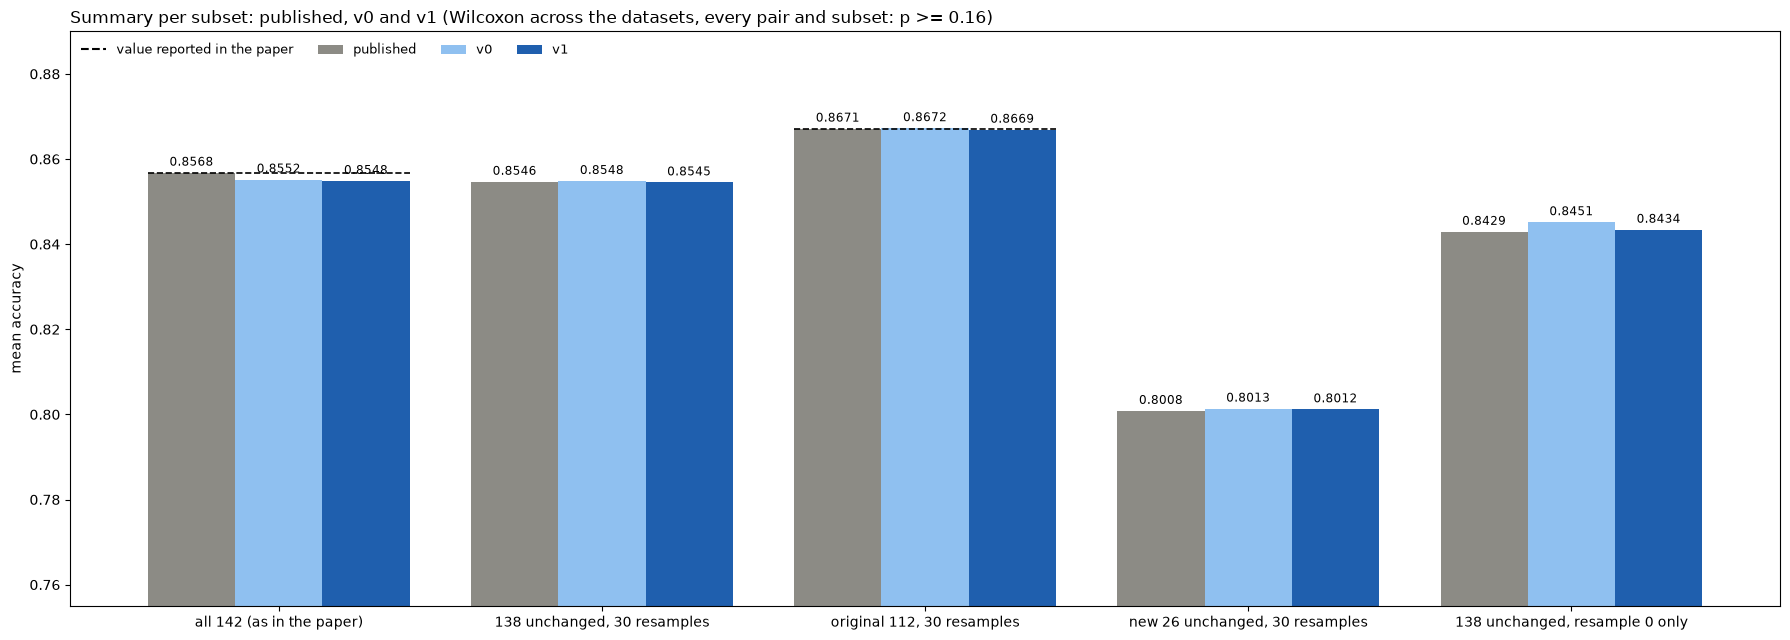

In [7]:
# the subsets: name, datasets, resamples, and the value reported in the paper (None = not reported)
NEW_UNCHANGED = [name for name in NEW30 if name in UNCHANGED]
SUBSETS = [("all 142 (as in the paper)", published.index, published.columns, PAPER_MEAN_142),
           ("138 unchanged, 30 resamples", UNCHANGED, published.columns, None),
           ("original 112, 30 resamples", ORIGINAL, published.columns, PAPER_MEAN_112),
           (f"new {len(NEW_UNCHANGED)} unchanged, 30 resamples", NEW_UNCHANGED, published.columns, None),
           ("138 unchanged, resample 0 only", UNCHANGED, ["0"], None)]

summary_rows = []
p_values = []                                           # every pair in every subset
for subset, datasets, resamples, paper in SUBSETS:
    row = {"subset": subset, "paper_reported": paper}
    for name, table in RESULTS.items():
        row[name] = table.loc[datasets, resamples].mean(axis=1).mean()     # the mean of the per-dataset means
    summary_rows.append(row)
    for a, b in PAIRS:                                  # Wilcoxon across the datasets (per-dataset means)
        mean_a = RESULTS[a].loc[datasets, resamples].mean(axis=1)
        mean_b = RESULTS[b].loc[datasets, resamples].mean(axis=1)
        p_values.append(stats.wilcoxon(mean_a, mean_b).pvalue)
summary = pd.DataFrame(summary_rows).set_index("subset")

fig, ax = plt.subplots(figsize=(18, 6.5))
x = np.arange(len(summary))
for offset, name in zip([-0.27, 0, 0.27], RESULTS):
    bars = ax.bar(x + offset, summary[name], 0.27, color=VERSION_COLORS[name], label=name)
    ax.bar_label(bars, fmt="{:.4f}", padding=3, fontsize=8.5)
for xi, paper in zip(x, summary["paper_reported"]):
    if pd.notna(paper):                                                   # the paper's value: a dashed line
        ax.plot([xi - 0.405, xi + 0.405], [paper, paper], color="black", linestyle="--", linewidth=1.2)
ax.plot([], [], color="black", linestyle="--", label="value reported in the paper")     # only for the legend
ax.set_xticks(x, summary.index)
ax.set_ylim(0.755, 0.89)
ax.set_ylabel("mean accuracy")
ax.set_title(f"Summary per subset: published, v0 and v1 (Wilcoxon across the datasets, every pair and subset: "
             f"p >= {min(p_values):.2f})", loc="left")
ax.legend(loc="upper left", frameon=False, fontsize=9, ncol=4)
plt.tight_layout()
plt.show()

## 7. Four views of the agreement (the 138 unchanged datasets)

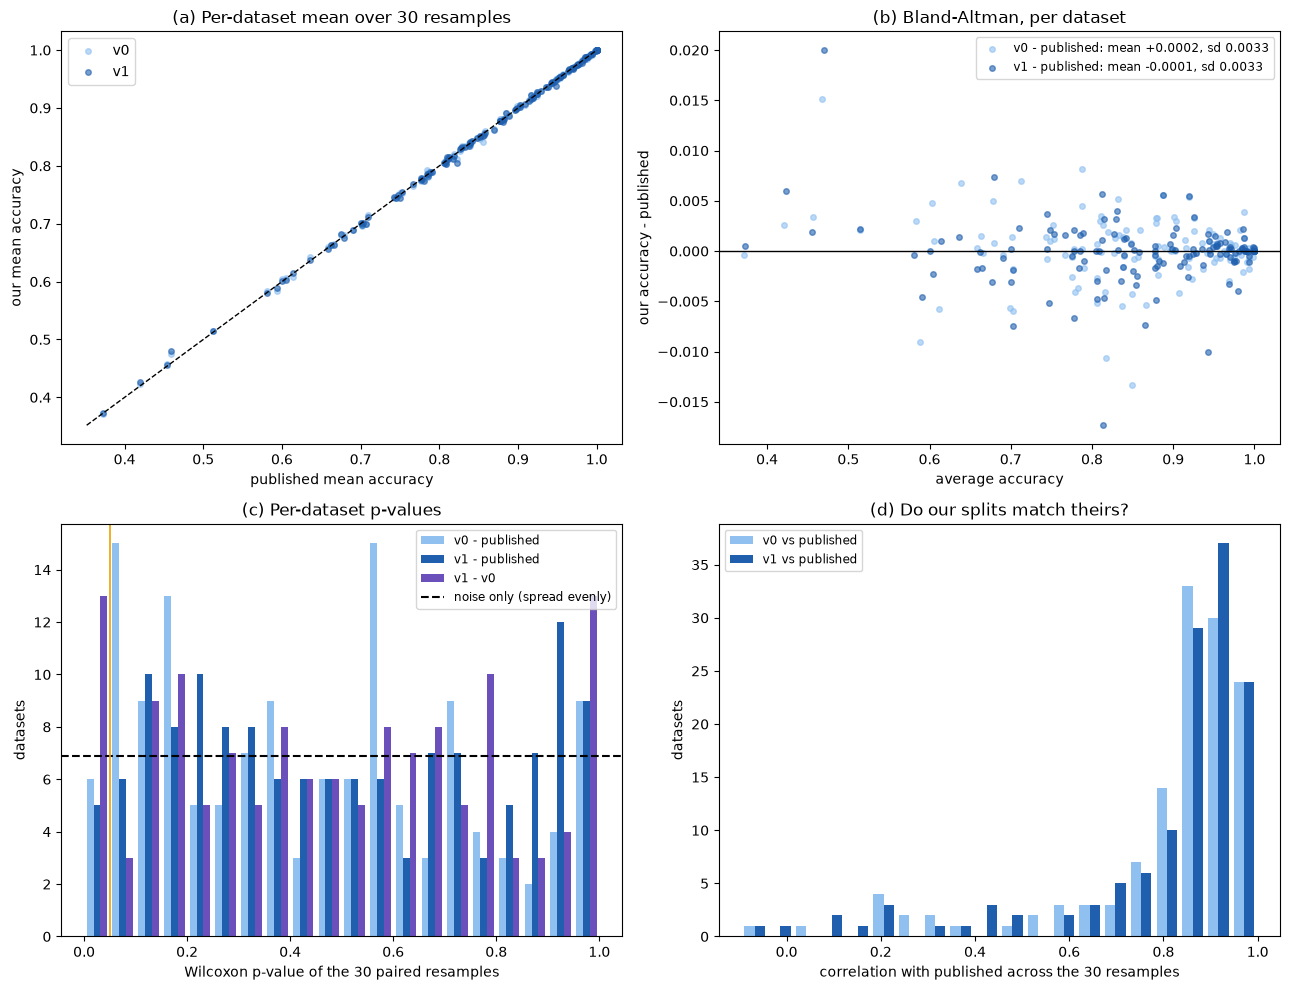

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
mean = {name: table.mean(axis=1) for name, table in SAME.items()}           # the per-dataset means (138 datasets)

# (a) per-dataset mean accuracy: v0 and v1 against published
ax = axes[0, 0]
for name in ["v0", "v1"]:
    ax.scatter(mean["published"], mean[name], color=VERSION_COLORS[name], alpha=0.6, s=16, label=name)
lo = min(mean["published"].min(), mean["v0"].min(), mean["v1"].min()) - 0.02
ax.plot([lo, 1], [lo, 1], "k--", linewidth=1)                               # the diagonal: the same mean
ax.set(xlabel="published mean accuracy", ylabel="our mean accuracy", title="(a) Per-dataset mean over 30 resamples")
ax.legend()

# (b) Bland-Altman: the difference against the average, per dataset
ax = axes[0, 1]
for name in ["v0", "v1"]:
    d = per_pair[f"{name} - published"]["diff"]
    ax.scatter((mean["published"] + mean[name]) / 2, d, color=VERSION_COLORS[name], alpha=0.6, s=16,
               label=f"{name} - published: mean {d.mean():+.4f}, sd {d.std():.4f}")
ax.axhline(0, color="k", linewidth=1)
ax.set(xlabel="average accuracy", ylabel="our accuracy - published", title="(b) Bland-Altman, per dataset")
ax.legend(fontsize=8.5)

# (c) the per-dataset p-values of the three pairs: with noise only they are spread evenly between 0 and 1
ax = axes[1, 0]
bins = np.linspace(0, 1, 21)
ax.hist([d["p"] for d in per_pair.values()], bins=bins, color=list(PAIR_COLORS.values()), label=list(per_pair))
ax.axhline(len(UNCHANGED) / (len(bins) - 1), color="k", linestyle="--", label="noise only (spread evenly)")
ax.axvline(0.05, color=WARNING, linewidth=1.2)
ax.set(xlabel="Wilcoxon p-value of the 30 paired resamples", ylabel="datasets", title="(c) Per-dataset p-values")
ax.legend(fontsize=8.5)

# (d) split correlation: are the easy and the hard splits the same for both?
ax = axes[1, 1]
ax.hist([per_pair[f"{name} - published"]["split_corr"].dropna() for name in ["v0", "v1"]], bins=20,
        color=[VERSION_COLORS["v0"], VERSION_COLORS["v1"]], label=["v0 vs published", "v1 vs published"])
ax.set(xlabel="correlation with published across the 30 resamples", ylabel="datasets",
       title="(d) Do our splits match theirs?")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

# Part B - The paper's timing claim: v1 on one CPU core

The paper: under 15 minutes for all 142 datasets on one CPU core. v1 times the same parts (the QUANT transform, fit, predict; not reading the files); every resample is one measurement.

## 8. Total time for all 142 datasets, per resample

Left: the mean over the 30 resamples by phase (whiskers: the fastest and the slowest resample; dashed: the paper's
claim). Right: every resample.

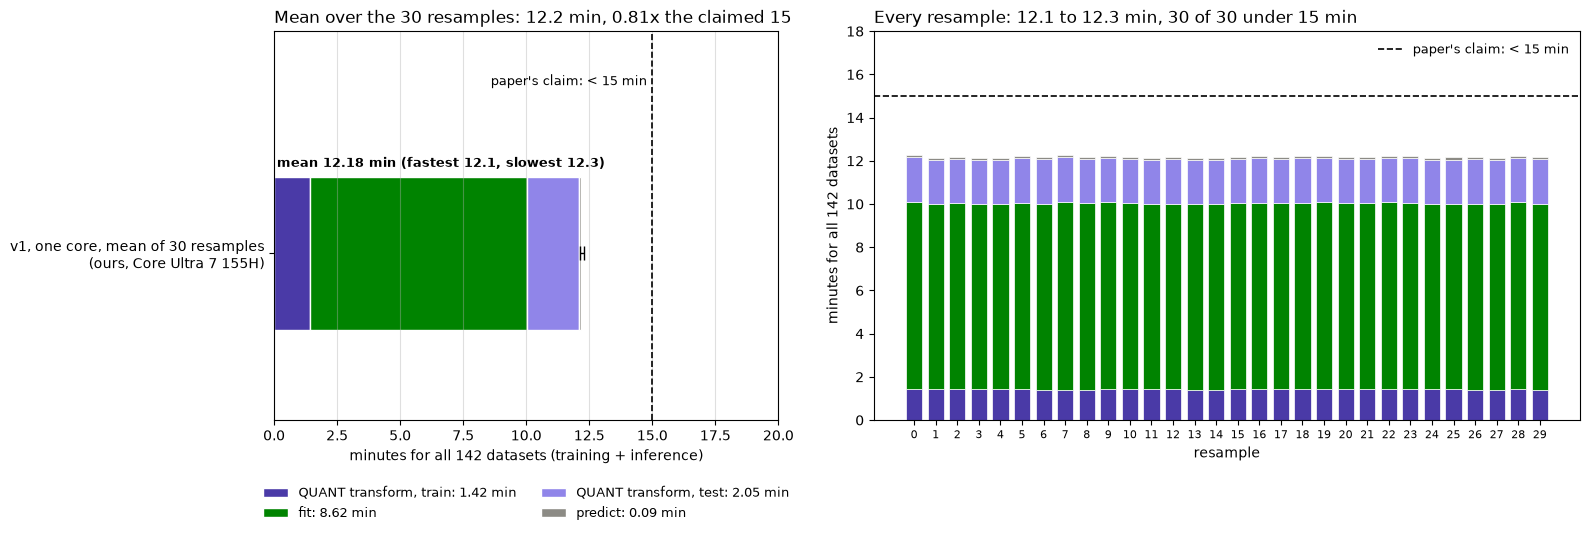

In [9]:
per_resample = v1_runs.groupby("resample")[list(PHASES)].sum() / 60      # minutes per phase, all 142 datasets
totals = per_resample.sum(axis=1)                                         # minutes per resample
mean_phases = per_resample.mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})

# left: the mean of our 30 resamples, split into the phases, against the paper's claim
ax = axes[0]
left = 0.0
for column, (label, color) in PHASES.items():
    ax.barh(0, mean_phases[column], 0.55, left=left, color=color, edgecolor="white",
            label=f"{label}: {mean_phases[column]:.2f} min")
    left += mean_phases[column]
low, high = totals.mean() - totals.min(), totals.max() - totals.mean()     # whiskers: the fastest, the slowest resample
ax.errorbar(totals.mean(), 0, xerr=[[low], [high]], color="black", capsize=5, linewidth=1)
ax.annotate(f"mean {totals.mean():.2f} min (fastest {totals.min():.1f}, slowest {totals.max():.1f})", (0, 0.28),
            xytext=(2, 4), textcoords="offset points", ha="left", va="bottom", fontsize=9.5, fontweight="bold")
ax.axvline(PAPER_CLAIM_MIN, color="black", linestyle="--", linewidth=1.2)
ax.annotate("paper's claim: < 15 min", (PAPER_CLAIM_MIN, 0.62), xytext=(-4, 0), textcoords="offset points",
            ha="right", va="center", fontsize=9)
ax.set_yticks([0], ["v1, one core, mean of 30 resamples\n(ours, Core Ultra 7 155H)"])
ax.set_xlim(0, max(20, totals.max() * 1.15))
ax.set_ylim(-0.6, 0.8)
ax.set_xlabel("minutes for all 142 datasets (training + inference)")
ax.set_title(f"Mean over the 30 resamples: {totals.mean():.1f} min, {totals.mean() / PAPER_CLAIM_MIN:.2f}x the claimed 15", loc="left")
ax.grid(True, axis="x", alpha=0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, fontsize=9)

# right: every resample on its own, split into the phases
ax = axes[1]
bottom = np.zeros(len(per_resample))
for column, (label, color) in PHASES.items():
    ax.bar(per_resample.index, per_resample[column], 0.75, bottom=bottom, color=color, edgecolor="white", linewidth=0.5)
    bottom += per_resample[column].values
ax.axhline(PAPER_CLAIM_MIN, color="black", linestyle="--", linewidth=1.2, label="paper's claim: < 15 min")
ax.set_xticks(per_resample.index)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylim(0, max(PAPER_CLAIM_MIN, totals.max()) * 1.2)
ax.set_xlabel("resample")
ax.set_ylabel("minutes for all 142 datasets")
ax.set_title(f"Every resample: {totals.min():.1f} to {totals.max():.1f} min, "
             f"{(totals < PAPER_CLAIM_MIN).sum()} of {len(totals)} under 15 min", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 9. Where the time goes

Mean seconds per run over the 30 resamples: the 15 slowest datasets, and all the other datasets together.

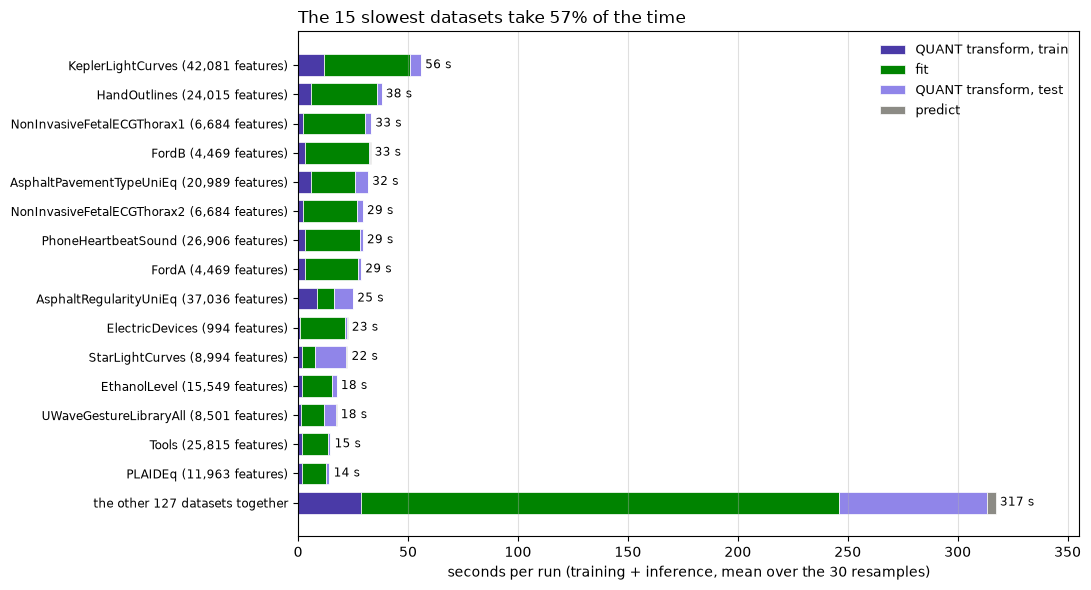

In [10]:
phases = list(PHASES)
per_ds = v1_runs.groupby("dataset")[phases + ["n_features"]].mean()       # mean seconds per run of each dataset
per_ds["total"] = per_ds[phases].sum(axis=1)
slowest = per_ds.sort_values("total", ascending=False)
rest = slowest.iloc[15:][phases].sum().rename(f"the other {len(slowest) - 15} datasets together")
time_rows = pd.concat([slowest.head(15)[phases], rest.to_frame().T])      # the 15 slowest datasets + one row for the rest

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(time_rows))[::-1]                                       # the slowest at the top
left = np.zeros(len(time_rows))
for column, (label, color) in PHASES.items():
    bars = ax.barh(y, time_rows[column], 0.75, left=left, color=color, edgecolor="white", linewidth=0.5, label=label)
    left += time_rows[column].values
ax.bar_label(bars, labels=[f"{value:.0f} s" for value in left], padding=3, fontsize=8.5)    # the total, after the last phase
labels = [f"{name} ({per_ds.loc[name, 'n_features']:,.0f} features)" if name in per_ds.index else name
          for name in time_rows.index]
ax.set_yticks(y, labels, fontsize=8.5)
ax.set_xlim(0, left.max() * 1.12)
ax.set_xlabel("seconds per run (training + inference, mean over the 30 resamples)")
ax.set_title(f"The 15 slowest datasets take {slowest.head(15)['total'].sum() / per_ds['total'].sum():.0%} of the time",
             loc="left")
ax.grid(True, axis="x", alpha=0.4)
ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 10. The results table: our numbers vs the paper's

Written to `results/comparison_with_paper.md` (README, section 5).

In [11]:
def accuracies(subset):
    """The mean accuracy of published, v0 and v1 on one subset of section 6, as text."""
    return [f"{summary.loc[subset, name]:.4f}" for name in RESULTS]

def md_row(cells):
    """One row of a Markdown table."""
    return "| " + " | ".join(cells) + " |"

vs_published = {name: per_pair[f"{name} - published"] for name in ["v0", "v1"]}      # the 138 unchanged datasets
table_rows = [
    ["Mean accuracy, all 142 datasets", f"{PAPER_MEAN_142:.4f}"] + accuracies("all 142 (as in the paper)"),
    ["Mean accuracy, the 112 original datasets", f"{PAPER_MEAN_112:.4f}"] + accuracies("original 112, 30 resamples"),
    ["Mean accuracy, the 138 unchanged datasets", "-"] + accuracies("138 unchanged, 30 resamples"),
    ["Datasets without a significant difference to the published results (138 unchanged, p >= 0.05)", "-", "-"]
    + [f"{d['within_noise'].sum()} of {len(d)}" for d in vs_published.values()],
    ["Time for all 142 datasets on one CPU core (minutes per resample)", f"under {PAPER_CLAIM_MIN}",
     "-", "- (no timers)", f"{totals.mean():.1f} ({totals.min():.1f} to {totals.max():.1f})"],
]
header = ["", "Paper", "Published results file", "v0: the authors' code, our run", "v1: with timers, our run"]
holm_counts = f"v0 {vs_published['v0']['significant_holm'].sum()}, v1 {vs_published['v1']['significant_holm'].sum()}"
lines = [
    "# QUANT: our results vs the paper",
    "",
    "Written by `notebooks/01_reproduction.ipynb` (section 10). 142 datasets x 30 resamples (resample 0 = the",
    "original UCR split, 1-29 = the bake-off redux splits), default settings (depth 6, div 4; ExtraTrees with 200 trees),",
    "one CPU core; v0 has no seed, v1 uses seed 0.",
    "",
    md_row(header),
    "|" + "---|" * len(header),                          # the line under the header
]
for row in table_rows:
    lines.append(md_row(row))
lines += [
    "",
    f"- 4 datasets ({', '.join(CORRECTED)}) were corrected after the paper; the published results were computed on",
    "  the old versions, so the method is compared on the other 138.",
    "- Per dataset: a two-sided Wilcoxon signed-rank test of the 30 paired resamples (p >= 0.05 = no significant",
    f"  difference). Datasets significant after the Holm correction: {holm_counts}.",
    "- Time: QUANT transform, fit and predict, data loading excluded, as in the paper. The paper's timings come from",
    "  the authors' cluster nodes (Intel Xeon), ours from an Intel Core Ultra 7 155H laptop.",
    "",
]
(RESULTS_DIR / "comparison_with_paper.md").write_text("\n".join(lines), encoding="utf-8")
print("written: results/comparison_with_paper.md")

written: results/comparison_with_paper.md


## 11. Conclusions

- **The accuracy reproduces:** on the 138 unchanged datasets no dataset differs significantly from the published
  results after Holm's correction, for v0 or v1 (before the correction 6 and 5 datasets have p < 0.05, about 7 would by
  chance), and across the datasets the Wilcoxon tests find no systematic difference. v1 differs from v0 only by seed
  noise (13 datasets below p = 0.05 before the correction, none after: the overlapping resamples make single-dataset
  tests optimistic): v1 is the baseline of every improvement.
- **The 4 changed datasets explain the gap on all 142:** 0.8552 (v0) and 0.8548 (v1) against 0.8568; on the 112
  original datasets 0.8672 and 0.8669 against 0.8671.
- **The timing claim holds:** 12.2 minutes per resample on one core (12.1 to 12.3), below the paper's claim of under 15
  minutes on every resample.